# Разработка A/B-тестирования и анализ результатов
- Автор: Чахлова Елизавета
- Дата: 05.10.2026

**Цель исследования**:
В развлекательном приложении с функцией "бесконечной" ленты существуют две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку. Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя.

Необходимо рассчитать параметры A/B-теста и оценить, повышает ли новый алгоритм рекомендаций
ключевые метрики вовлечённости и монетизации в приложении с «бесконечной» лентой

## Описание данных

У нас три таблицами:

- `sessions_project_history` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23. 

- `sessions_project_test_part` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14.

- `sessions_project_test` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02.

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).

### Работа с историческими данными (EDA)

In [1]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest

from math import ceil

In [2]:
# df_sessions_history = здесь была загрузка датасета

In [3]:
# выводим первые 5 строк датафрейма
df_sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


#### 1.2. Знакомство с данными
- Для каждого уникального пользователя `user_id` рассчитаем количество уникальных сессий `session_id`.

- Выведем на экран все данные из таблицы `sessions_history` для одного пользователя с наибольшим количеством сессий.

- Изучим таблицу для одного пользователя, чтобы лучше понять логику формирования каждого столбца данных.

In [4]:
# находим пользователя с наибольшим кол-вом сессий
top_user_id = df_sessions_history['user_id'].value_counts().idxmax()

# выводим на экран данные для пользователя с наибольшим кол-вом сессий
df_sessions_history[df_sessions_history['user_id'] == top_user_id]

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
124515,6A73CB5566BB494D,110E3F28C1F5415F,2025-08-28,2025-08-28 18:58:19,2025-08-28,1,0,3,MENA,Mac
196252,6A73CB5566BB494D,D68C8D98A0F1C439,2025-08-29,2025-08-29 20:53:27,2025-08-28,2,1,3,MENA,Mac
242428,6A73CB5566BB494D,6587D217472BF807,2025-08-30,2025-08-30 13:08:22,2025-08-28,3,1,1,MENA,Mac
304287,6A73CB5566BB494D,A9BC25593D056F8E,2025-09-01,2025-09-01 18:52:49,2025-08-28,4,1,2,MENA,Mac
346611,6A73CB5566BB494D,CB6F9C4191FAF6F6,2025-09-03,2025-09-03 22:49:08,2025-08-28,5,1,3,MENA,Mac
363510,6A73CB5566BB494D,9C609432F6E6535A,2025-09-04,2025-09-04 13:59:46,2025-08-28,6,1,4,MENA,Mac
391902,6A73CB5566BB494D,5D892E33B97A257A,2025-09-06,2025-09-06 18:46:55,2025-08-28,7,1,2,MENA,Mac
404322,6A73CB5566BB494D,22A9BD3861F49087,2025-09-07,2025-09-07 18:33:49,2025-08-28,8,1,3,MENA,Mac
415489,6A73CB5566BB494D,F70E351154B092DC,2025-09-08,2025-09-08 20:30:22,2025-08-28,9,1,4,MENA,Mac
425805,6A73CB5566BB494D,84A3DC0CFF449F53,2025-09-09,2025-09-09 16:36:04,2025-08-28,10,1,1,MENA,Mac


 **Промежуточный вывод. Логика формирования каждого столбца**
- `user_id` - уникальный идлентификатор одного пользователя
- `session_id` - уникальный идентификатор сессия, меняется при каждом новом заходе пользователя в приложение
- `session_date` - дата сессии
- `session_start_ts` - дата и время начала сессии, начало совпадает с `session_date`
- `install_date` - дата установки приложения не меняется
- `session_number` - номер сессии с каждым заходом приложение увеличивается на 1
- `registration_flag` - зарегестрированный ли пользователь. 1 - да, 0 - нет
- `page_counter` - кол-во просмотренных страниц во время сессии
- `region` - регион, скорее всего меняется редко
- `device` - устройство, скорее всего меняется редко

#### Анализ числа регистраций
- Агрегируем исторические данные и рассчитаем число уникальных пользователей и число зарегистрированных пользователей для каждого дня наблюдения.

- Построим линейные графики общего числа пользователей и общего числа зарегистрированных пользователей по дням.

- Построим отдельный линейный график доли зарегистрированных пользователей от всех пользователей по дням.

In [5]:
# уникальные пользователи за день
unique_users = df_sessions_history.groupby('session_date')['user_id'].nunique()

# уникальные зарегистрированные пользователи за день
registred_users = df_sessions_history[df_sessions_history['registration_flag'] == 1].groupby('session_date')['user_id'].nunique()

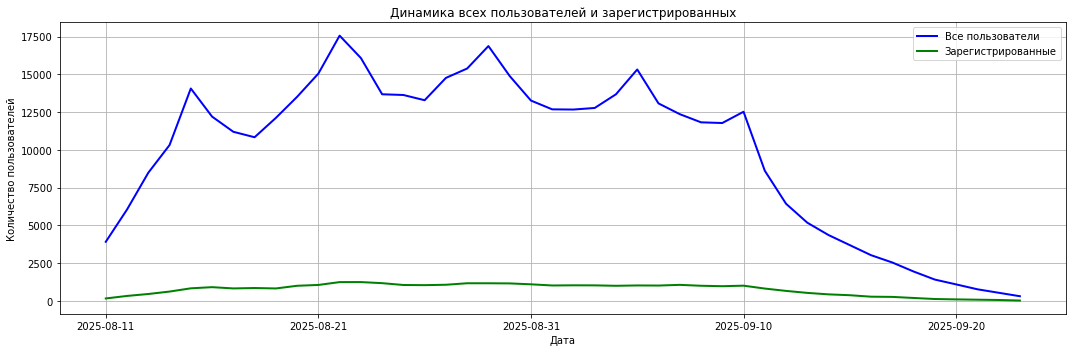

In [6]:
# Строим линейные графики
plt.figure(figsize=(15, 5))
unique_users.plot(
    linewidth=2, # толщина линий
    color='blue' # цвет линии
)
registred_users.plot(
    linewidth=2,  # толщина линий
    color='green' # цвет линии
)

# Настройка оформления
plt.title('Динамика всех пользователей и зарегистрированных')
plt.xlabel('Дата')
plt.ylabel('Количество пользователей')
plt.legend(['Все пользователи', 'Зарегистрированные'])
plt.grid(True)

plt.tight_layout()
plt.show()

In [7]:
# считаем долю зарегистрированных пользователей от всех пользователей по дням
part_users = (registred_users/unique_users)*100

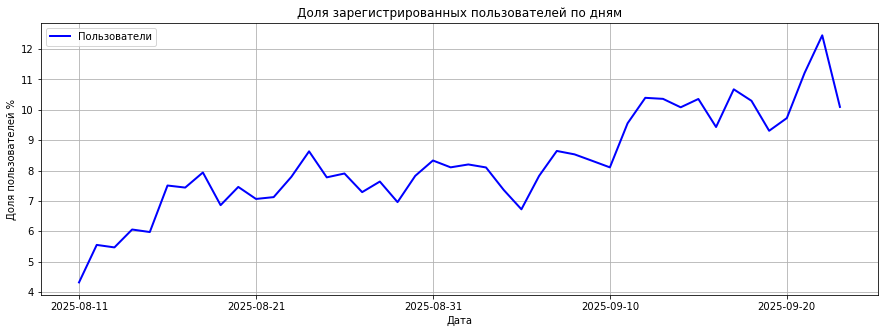

In [8]:
# Строим линейный график
plt.figure(figsize=(15, 5))
part_users.plot(
    linewidth=2, # толщина линий
    color='blue', # цвет линии
    title = 'Доля зарегистрированных пользователей по дням',
    xlabel = 'Дата',
    ylabel = 'Доля пользователей %',
    label = 'Пользователи', # задаем текст для легенды
    legend=True,  # включаем легенду
    grid = True  # включаем сетку
)

plt.show()

**Промежуточный вывод**
- На графике с динамикой всех пользователей видно, что с 10.09.2025 по 23.09.2025 идет резкое снижение кол-ва пользователей в приложении. Нужно проанализировать и найти причины
- На графике с динамикой доли зарегистрированных пользоватей видно, что идет тренд на увеличение доли регистраций.

#### Анализ числа просмотренных страниц
- Построим столбчатую диаграмму, где по оси X будет число просмотренных страниц, по оси Y — количество сессий.

In [9]:
# считаем сумму первых сессий по кол-ву просматриваемых страниц
pages_viewed = df_sessions_history[df_sessions_history['session_number'] == 1].groupby('page_counter')['session_id'].nunique()

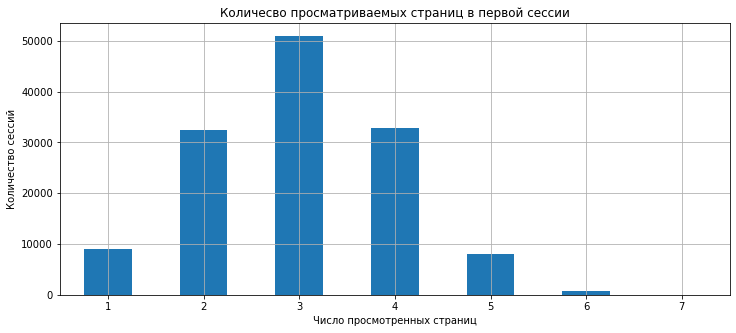

In [10]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 5))

# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
pages_viewed.plot(
               kind='bar', # Тип графика - столбчатая диаграмма
               rot=360, # Градус вращения подписи по оси Х
               title=f'Количесво просматриваемых страниц в первой сессии',
               xlabel='Число просмотренных страниц',
               ylabel='Количество сессий',
               grid=True
)

# Выводим график
plt.show()

**Промежуточный вывод**
- Больше всего пользователи просматривают 3 страницы во время первой сессии. А так же лидируют значения 2 и 4. 

#### Доля пользователей, просмотревших более четырёх страниц
- В датафрейме `sessions_history` создаем дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если было просмотрено меньше.

- Построим график со средним значением доли успешных первых сессий от всех первых сессий пользователей.

In [11]:
# создаем дополнительных столбец good_session с дефолтным значением 0
df_sessions_history['good_session'] = 0

# если просмотрено 4 и более страниц за сессию, то присваиваем good_session значение 1
df_sessions_history.loc[df_sessions_history['page_counter'] > 3,'good_session'] = 1

In [12]:
# количество первых сессий за день
session_count = df_sessions_history[df_sessions_history['session_number'] == 1].groupby('session_date')['session_number'].count()
good_session_count = df_sessions_history[(df_sessions_history['session_number'] == 1)&(df_sessions_history['good_session'] == 1)].groupby('session_date')['session_number'].count()

In [13]:
# доля успешных первых сессий
part_good_session = (good_session_count/session_count)*100

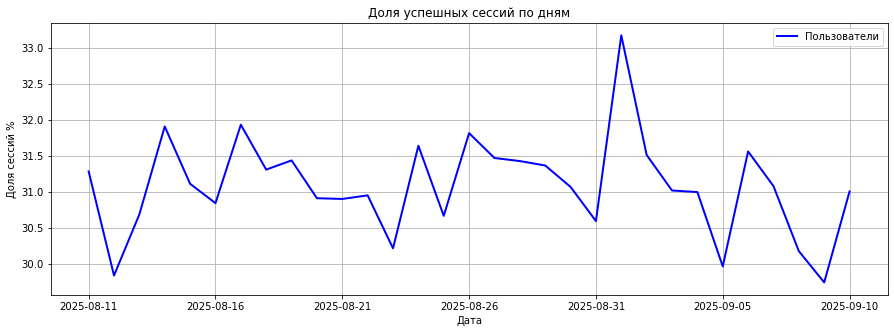

In [14]:
# Строим линейный график
plt.figure(figsize=(15, 5))
part_good_session.plot(
    linewidth=2, # толщина линий
    color='blue', # цвет линии
    title = 'Доля успешных сессий по дням',
    xlabel = 'Дата',
    ylabel = 'Доля сессий %',
    label = 'Пользователи', # задаем текст для легенды
    legend=True,  # включаем легенду
    grid = True  # включаем сетку
)

plt.show()

**Промежуточный вывод**
- Доля успешных первых сессий значительно не меняется за период наблюдений и лежит в диапазоне от 29% до 33%.

### Подготовка к тесту

####  Расчёт размера выборки

In [15]:
# Задаем параметры:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 1 - beta  # Мощность теста
p = 0.3 # Базовый уровень доли
# mde = 0.03  # Минимальный детектируемый эффект
mde = p*0.03
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


#### Расчёт длительности A/B-теста

- Рассчитаем среднее количество уникальных пользователей приложения в день.

- Определим длительность теста исходя из рассчитанного значения размера выборок и среднего дневного трафика приложения. Количество дней округлите в большую сторону.

In [16]:
# Среднее количество пользователей приложения в день по историческим данным
avg_daily_users = unique_users.mean()

# Рассчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = ceil((sample_size*2)/avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровне трафика в {avg_daily_users} пользователей в день составит {test_duration} дней")

Рассчитанная длительность A/B-теста при текущем уровне трафика в 9907.363636363636 пользователей в день составит 9 дней


### Мониторинг А/В-теста

#### Проверка распределения пользователей

- Рассчитаем количество уникальных пользователей в каждой из экспериментальных групп для одного дня наблюдения.

- Рассчитаем процентную разницу в количестве пользователей в группах A и B.

In [17]:
# df_sessions_test_part = здесь была загрузка датафрейма

In [18]:
# выводим первые 5 строк датафрейма
df_sessions_test_part.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,3404844B53442747,B4901323BD537E45,2025-10-14,2025-10-14 19:28:49,2025-10-14,1,0,3,CIS,Android,B
1,3A2BF4D364E62D89,216FC619308F8788,2025-10-14,2025-10-14 21:11:04,2025-10-14,1,0,3,MENA,iPhone,A
2,79CDAE11E32B1597,EDFCE4AC1A504074,2025-10-14,2025-10-14 21:44:03,2025-10-14,1,0,3,CIS,iPhone,A
3,D6AF8D78297A931F,CF0AC0EEDE92C690,2025-10-14,2025-10-14 19:07:55,2025-10-14,1,0,4,CIS,PC,A
4,37E0CE723AE568E0,2E6ED45E8C86C4E9,2025-10-14,2025-10-14 15:39:44,2025-10-14,1,0,3,CIS,Mac,B


In [19]:
# считаем кол-во уникальных пользователей в каждой из групп
unique_users_test = df_sessions_test_part.groupby('test_group')['user_id'].nunique()
unique_users_test

test_group
A    1477
B    1466
Name: user_id, dtype: int64

In [20]:
p = 100*((unique_users_test.loc['A'] - unique_users_test.loc['B'])/unique_users_test.loc['A'])

print(f"Процентная разниме мужду группой A и B составляет - {p}%")

Процентная разниме мужду группой A и B составляет - 0.7447528774542992%


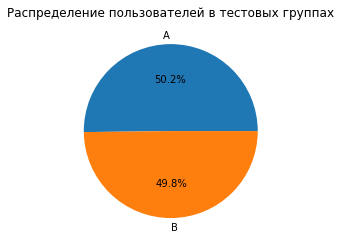

In [21]:
unique_users_test.plot(
    title=f'Распределение пользователей в тестовых группах',
    ylabel='',
    xlabel='',
    kind='pie',
    autopct='%1.1f%%',          # показываем проценты
    legend=False               # убираем легенду
)
plt.show()

**Промежуточный вывод**
- Разница в кол-ве пользователей между группами незначительная и составляет 0.75%

#### Проверка пересечений пользователей
- Рассчитаем количество пользователей, которые встречаются одновременно в группах A и B

In [22]:
group_A = df_sessions_test_part[df_sessions_test_part['test_group'] == 'A']['user_id']
group_B = df_sessions_test_part[df_sessions_test_part['test_group'] == 'B']['user_id']

intersection = list(set(group_A) & set(group_B))
print(intersection) 

[]


**Промежуточный вывод**
- Пересечение между группами отсутствует

#### Равномерность разделения пользователей по устройствам

Построим две диаграммы:

- доля каждого типа устройства для пользователей из группы A,

- доля каждого типа устройства для пользователей из группы B.

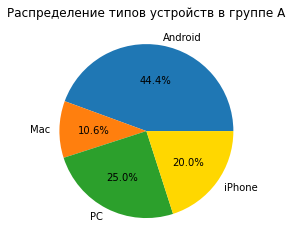

In [23]:
group_A_device = df_sessions_test_part[df_sessions_test_part['test_group'] == 'A'].groupby('device')['user_id'].nunique()
order = ['Android', 'Mac', 'PC', 'iPhone'] # Задаем нужный порядок категорий
group_A_device_ordered = group_A_device.reindex(order) # Изменяем порядок, чтобы упорядочить группы на круговой диаграмме

colors_list = ['#1f77b4', '#ff7f0e', '#2ca02c', '#ffd700'] # Задаем цвета для диаграммы
group_A_device_ordered.plot(
    title=f'Распределение типов устройств в группе A',
    ylabel='',
    xlabel='',
    kind='pie',
    colors=colors_list,
    autopct='%1.1f%%',          # показываем проценты
    legend=False               # убираем легенду
)
plt.show()

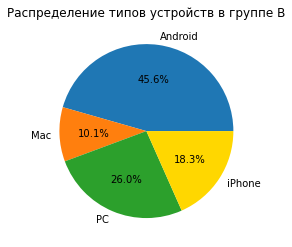

In [24]:
group_B_device = df_sessions_test_part[df_sessions_test_part['test_group'] == 'B'].groupby('device')['user_id'].nunique()
group_B_device_ordered = group_B_device.reindex(order)
group_B_device_ordered.plot(
    title=f'Распределение типов устройств в группе B',
    ylabel='',
    xlabel='',
    kind='pie',
    colors=colors_list,
    autopct='%1.1f%%',          # показываем проценты
    legend=False               # убираем легенду
)
plt.show()

**Промежуточный вывод**
- Распределение по типам устройст практически идентично в обеих группах

`Группа А`:
- Android - 656
- Mac - 156
- PC - 369
- iPhone - 296

`Группа В`:
- Android - 668
- Mac - 148
- PC - 381
- iPhone - 269

#### Равномерность распределения пользователей по регионам

Построим две диаграммы:

- доля каждого региона для пользователей из группы A,

- доля каждого региона для пользователей из группы B.

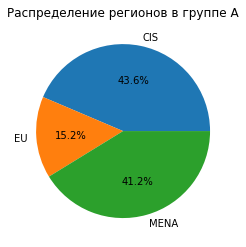

In [25]:
group_A_region = df_sessions_test_part[df_sessions_test_part['test_group'] == 'A'].groupby('region')['user_id'].nunique()
order = ['CIS', 'EU', 'MENA'] # Задаем нужный порядок категорий
group_A_region_ordered = group_A_region.reindex(order) # Изменяем порядок, чтобы упорядочить группы на круговой диаграмме

colors_list = ['#1f77b4', '#ff7f0e', '#2ca02c'] # Задаем цвета для диаграммы
group_A_region_ordered.plot(
    title=f'Распределение регионов в группе A',
    ylabel='',
    xlabel='',
    kind='pie',
    colors=colors_list,
    autopct='%1.1f%%',          # показываем проценты
    legend=False               # убираем легенду
)
plt.show()

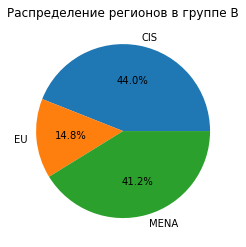

In [26]:
group_B_region = df_sessions_test_part[df_sessions_test_part['test_group'] == 'B'].groupby('region')['user_id'].nunique()
group_B_region_ordered = group_B_region.reindex(order) # Изменяем порядок, чтобы упорядочить группы на круговой диаграмме

group_B_region_ordered.plot(
    title=f'Распределение регионов в группе B',
    ylabel='',
    xlabel='',
    kind='pie',
    colors=colors_list,
    autopct='%1.1f%%',          # показываем проценты
    legend=False               # убираем легенду
)
plt.show()

In [27]:
group_B_region_ordered

region
CIS     645
EU      217
MENA    604
Name: user_id, dtype: int64

**Промежуточный вывод**
- Распределение по регионам также идентично в обеих группах

`Группа А`:
- CIS - 644
- EU - 224
- MENA - 609

`Группа В`:
- CIS - 645
- EU - 217
- MENA - 604

#### Вывод после проверки A/B-теста
- На графике с динамикой всех пользователей видно, что с 10.09.2025 по 23.09.2025 идет резкое снижение кол-ва пользователей в приложении. Нужно проанализировать и найти причины
- На графике с динамикой доли зарегистрированных пользоватей видно, что идет тренд на увеличение доли регистраций.
- Больше всего пользователи просматривают 3 страницы во время первой сессии. А так же лидируют значения 2 и 4
- Доля успешных первых сессий значительно не меняется за период наблюдений и лежит в диапазоне от 29% до 33%

- Необходимый размер выборки для каждой группы: 3761 пользователей
- Рассчитанная длительность A/B-теста при текущем уровне трафика в 9907 пользователей в день составит 9 дней
- Разница в кол-ве пользователей между группами незначительная и составляет 0.75%
- Пересечение между группами отсутствует. Выборки независимые
- Распределение по типам устройств и регионам различается незначительно на 1-2%


### Проверка результатов A/B-теста

#### Получение результатов теста и подсчёт основной метрики

In [28]:
# df_sessions_test = здесь была загрузка датафрейма
df_sessions_test.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B


In [29]:
# создаем дополнительных столбец good_session с дефолтным значением 0
df_sessions_test['good_session'] = 0

# если просмотрено 4 и более страниц за сессию, то присваиваем good_session значение 1
df_sessions_test.loc[df_sessions_test['page_counter'] > 3,'good_session'] = 1

#### Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик

**Нулевая и альтернативная гипотезы:**
- `H0` - Доля успешных сессий в группе А равна доле успешных сессий в группе В
- `H1` - Доля успешных сессий в группе В больше доли успешных сессий в группе А

В качестве `прокси метрик` можно выбрать кол-во кликов на предложенный контент, клики на рекламные баннеры (если они есть), время сессии.
А в качестве `барьерных метрик` - кол-во регистраций пользователей, либо наоборот кол-во удалений аккаунтов, число жалоб на контент.

#### Сравнение доли успешных первых сессий

In [30]:
mask_sn = df_sessions_test['session_number'] == 1
mask_gs = df_sessions_test['good_session'] == 1
mask_tg_A = df_sessions_test['test_group'] == 'A'
mask_tg_B = df_sessions_test['test_group'] == 'B'

all_session_A = df_sessions_test[(mask_tg_A)&(mask_sn)].shape[0]    # считаем все сессии
good_session_A = df_sessions_test[(mask_tg_A)&(mask_gs)&(mask_sn)].shape[0]    # считаем успешные сиссии
part_good_session_A = round((good_session_A/all_session_A*100), 2)    # доля успешных сессий в процентах

all_session_B = df_sessions_test[(mask_tg_B)&(mask_sn)].shape[0]    # считаем все сессии
good_session_B = df_sessions_test[(mask_tg_B)&(mask_gs)&(mask_sn)].shape[0]    # считаем успешные сиссии
part_good_session_B = round((good_session_B/all_session_B*100), 2)    # доля успешных сессий в процентах

delta = round((part_good_session_B - part_good_session_A), 3) # разница доли между группами

print(
    f"Доля успешных первых сессий группы A составляет - {part_good_session_A}%.\n"
    f"Доля успешных первых сессий группы B составляет - {part_good_session_B}%.\n"
    f"Процентная разниме мужду группой A и B составляет - {delta}%"
)

Доля успешных первых сессий группы A составляет - 31.57%.
Доля успешных первых сессий группы B составляет - 31.47%.
Процентная разниме мужду группой A и B составляет - -0.1%


#### Насколько статистически значимо изменение ключевой метрики
- Используя статистический тест, рассчитаем, является ли изменение в метрике доли успешных первых сессий статистически значимым.

In [31]:
# Фиксируем уровень значимости
alpha = 0.05
n_a, n_b = all_session_A, all_session_B # Берём предыдущие значения по размерам выборок A и B 
m_a, m_b = good_session_A, good_session_B # Берём предыдущие значения по количеству успехов в выборках A и B 

stat_ztest, p_value_ztest = proportions_ztest(
    [m_a, m_b],
    [n_a, n_b],
    alternative='smaller' # так как H_1: p_a < p_b
)

if p_value_ztest > alpha:
    print(f'pvalue={p_value_ztest} > {alpha}')
    print('Не получилось отвергнуть нулевую гипотезу')
else:
    print(f'pvalue={p_value_ztest} < {alpha}')
    print('Отвергаем нулевую гипотезу') 

pvalue=0.5783523649187868 > 0.05
Не получилось отвергнуть нулевую гипотезу


#### Вывод по результатам A/B-эксперимента

Был проведен А/В-тест с новым алгоритмом рекомендательной системы для авторизованных и неавторизованных пользователей. В тесте участвовали 2 группы по 41040 пользователей, длительность эксперимента составляла 9 день.
Для анализа результатов был добавлен признак успешности сессии, сессия считалась успешной если просмотрено 4 и более страниц. 

По итогам эксперимента: 
- Доля успешных первых сессий группы A составляет - 31.57%.
- Доля успешных первых сессий группы B составляет - 31.47%.
- Процентная разниме мужду группой A и B составляет - -0.1%

Полученное значение pvalue=0.578, что больше уровня значимости 0.05. 
На основании этого можно сделать вывод, что не получили статистически значимых результатов! **Не удалось подвердить, что новая рекомендательная система работает более эфферктивно.**
**Нововведение не стоит внедрять в приложение.**